# Facebook Metrics Analysis
Session 26 · Task 1

## 1. Load and inspect
Source: https://www.kaggle.com/datasets/masoodanzar/facebook-metrics
Place the original CSV in `data/facebook/`. Separator detection supports the original semicolon-delimited file. Raw data are not redistributed. Run all cells to create statistics, figures and a short report.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT / 'data').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'data').is_dir(), 'Open this notebook from the project root or notebooks folder.'
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
OUT = ROOT / 'reports'
FIG = ROOT / 'figures'
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches='tight')
    plt.show()
def require_columns(frame, columns):
    missing = set(columns) - set(frame.columns)
    if missing: raise ValueError(f'Missing required columns: {sorted(missing)}')
def report(name, text):
    (OUT / name).write_text(text, encoding='utf-8')
    print(text)

In [2]:
DATA = ROOT / 'data' / 'facebook'
files = list(DATA.rglob('*.csv'))
if len(files) != 1: raise FileNotFoundError('Place exactly one Facebook CSV in data/facebook/.')
raw = pd.read_csv(files[0], sep=None, engine='python')
raw.columns = raw.columns.str.strip()
display(raw.head()); raw.info()
display(raw.isna().sum().sort_values(ascending=False).to_frame('missing'))

,Page total likes,Type,Category,Post Month,Post Weekday,Post Hour,Paid,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,like,share,Total Interactions
0,139441,Photo,2,12,4,3,0.0,2752,5091,178,109,159,3078,1640,119,4,79.0,17.0,100
1,139441,Status,2,12,3,10,0.0,10460,19057,1457,1361,1674,11710,6112,1108,5,130.0,29.0,164
2,139441,Photo,3,12,3,3,0.0,2413,4373,177,113,154,2812,1503,132,0,66.0,14.0,80
3,139441,Photo,2,12,2,10,1.0,50128,87991,2211,790,1119,61027,32048,1386,58,1572.0,147.0,1777
4,139441,Photo,2,12,2,3,0.0,7244,13594,671,410,580,6228,3200,396,19,325.0,49.0,393


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                                                               Non-Null Count  Dtype  
---  ------                                                               --------------  -----  
 0   Page total likes                                                     500 non-null    int64  
 1   Type                                                                 500 non-null    object 
 2   Category                                                             500 non-null    int64  
 3   Post Month                                                           500 non-null    int64  
 4   Post Weekday                                                         500 non-null    int64  
 5   Post Hour                                                            500 non-null    int64  
 6   Paid                                                                 499 non-null    float64
 7   Lifetime

,missing
share,4
Paid,1
like,1
Category,0
Type,0
Page total likes,0
Post Month,0
Lifetime Post Total Reach,0
Lifetime Post Total Impressions,0
Post Weekday,0


## 2. Clean and document decisions
Remove exact duplicate rows only. Missing engagement is unknown, not zero. Convert numeric fields explicitly; invalidate negative counts and impossible calendar codes. Weekdays remain dataset codes because their mapping is not confirmed. No engagement imputation is used.

In [3]:
df = raw.drop_duplicates().copy()
require_columns(df, ['Type','Category','Post Month','Post Weekday','Post Hour','like','comment','share','Lifetime Post Total Reach','Lifetime Post Total Impressions'])
for c in df.columns:
    if c != 'Type':
        df[c] = pd.to_numeric(df[c], errors='coerce')
        df.loc[df[c] < 0, c] = np.nan
for c, lo, hi in [('Post Month',1,12),('Post Weekday',1,7),('Post Hour',0,23),('Paid',0,1)]:
    if c in df:
        valid = df[c].between(lo,hi) & (df[c] % 1 == 0)
        df.loc[~valid, c] = np.nan
df['Type'] = df['Type'].astype('string').str.strip().replace('',pd.NA)
df['engagement'] = df[['like','comment','share']].sum(axis=1, min_count=3)
df['engagement_per_100_reached'] = 100 * df.engagement / df['Lifetime Post Total Reach'].where(df['Lifetime Post Total Reach'] > 0)
# An interaction ratio, not the percentage of unique people engaging; it can exceed 100.
audit = pd.DataFrame({'raw_missing':raw.isna().sum(),'clean_missing':df.isna().sum()})
display(audit); display(df.describe(include='all').T)
print('Rows:',len(raw),'->',len(df),'Exact duplicates removed:',len(raw)-len(df))
print('Mean interactions:', np.nanmean(df.engagement), 'Median:', np.nanmedian(df.engagement))
audit.to_csv(OUT/'facebook_cleaning_audit.csv')

,raw_missing,clean_missing
Category,0.0,0
Lifetime Engaged Users,0.0,0
Lifetime People who have liked your Page and engaged with your post,0.0,0
Lifetime Post Consumers,0.0,0
Lifetime Post Consumptions,0.0,0
Lifetime Post Impressions by people who have liked your Page,0.0,0
Lifetime Post Total Impressions,0.0,0
Lifetime Post Total Reach,0.0,0
Lifetime Post reach by people who like your Page,0.0,0
Page total likes,0.0,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Page total likes,500.0,NaN,NaN,NaN,123194.176,16272.813214,81370.0,112676.0,129600.0,136393.0,139441.0
Type,500,4,Photo,426,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,500.0,NaN,NaN,NaN,1.88,0.852675,1.0,1.0,2.0,3.0,3.0
Post Month,500.0,NaN,NaN,NaN,7.038,3.307936,1.0,4.0,7.0,10.0,12.0
Post Weekday,500.0,NaN,NaN,NaN,4.15,2.030701,1.0,2.0,4.0,6.0,7.0
Post Hour,500.0,NaN,NaN,NaN,7.84,4.368589,1.0,3.0,9.0,11.0,23.0
Paid,499.0,NaN,NaN,NaN,0.278557,0.448739,0.0,0.0,0.0,1.0,1.0
Lifetime Post Total Reach,500.0,NaN,NaN,NaN,13903.36,22740.78789,238.0,3315.0,5281.0,13168.0,180480.0
Lifetime Post Total Impressions,500.0,NaN,NaN,NaN,29585.948,76803.24667,570.0,5694.75,9051.0,22085.5,1110282.0
Lifetime Engaged Users,500.0,NaN,NaN,NaN,920.344,985.016636,9.0,393.75,625.5,1062.0,11452.0


Rows: 500 -> 500 Exact duplicates removed: 0
Mean interactions: 213.77620967741936 Median: 125.0


## 3. Compare types, categories and publication timing
Use medians as well as means because viral posts can distort averages. Every comparison includes both total posts and nonmissing engagement observations. Groups with fewer than five observed outcomes are excluded from report rankings, but remain visible in tables.

Type


,posts,observed,mean_engagement,median_engagement,total_engagement,median_per_100_reached
Type,,,,,,
Video,7,7,295.857143,271.0,2071.0,0.545808
Status,45,45,217.044444,186.0,9767.0,1.530496
Photo,426,422,218.568720,123.5,92236.0,2.463432
Link,22,22,89.045455,52.5,1959.0,0.681011


Category


,posts,observed,mean_engagement,median_engagement,total_engagement,median_per_100_reached
Category,,,,,,
3.0,155,155,256.735484,163.0,39794.0,3.055159
2.0,130,130,264.161538,153.0,34341.0,3.055703
1.0,215,211,151.175355,92.0,31898.0,1.098901


Post Month


,posts,observed,mean_engagement,median_engagement,total_engagement,median_per_100_reached
Post Month,,,,,,
9.0,36,35,285.942857,199.0,10008.0,4.768856
5.0,37,37,256.297297,179.0,9483.0,3.084715
2.0,26,26,242.038462,174.0,6293.0,1.781950
7.0,52,52,328.500000,141.0,17082.0,2.203559
11.0,45,45,185.755556,126.0,8359.0,2.559330
4.0,50,50,217.520000,123.0,10876.0,2.015472
12.0,50,50,201.340000,115.0,10067.0,2.154397
1.0,25,25,160.600000,110.0,4015.0,2.083333
8.0,34,34,225.382353,105.0,7663.0,2.779098


... (2 outputs left out)

Post Hour


,posts,observed,mean_engagement,median_engagement,total_engagement,median_per_100_reached
Post Hour,,,,,,
20.0,1,1,280.000000,280.0,280.0,4.671338
17.0,3,3,157.333333,230.0,472.0,2.075306
13.0,52,52,245.019231,155.5,12741.0,2.079106
1.0,4,4,181.000000,143.5,724.0,3.912145
10.0,78,77,253.935065,139.0,19553.0,2.241059
3.0,105,105,228.590476,135.0,24002.0,2.605863
23.0,1,1,135.000000,135.0,135.0,4.783841
22.0,1,1,125.000000,125.0,125.0,0.607977
9.0,30,29,137.620690,122.0,3991.0,2.255892


Paid


,posts,observed,mean_engagement,median_engagement,total_engagement,median_per_100_reached
Paid,,,,,,
1.0,139,139,278.230216,158.0,38674.0,2.003173
NaN,1,1,119.000000,119.0,119.0,2.841452
0.0,360,356,188.876404,118.0,67240.0,2.221792


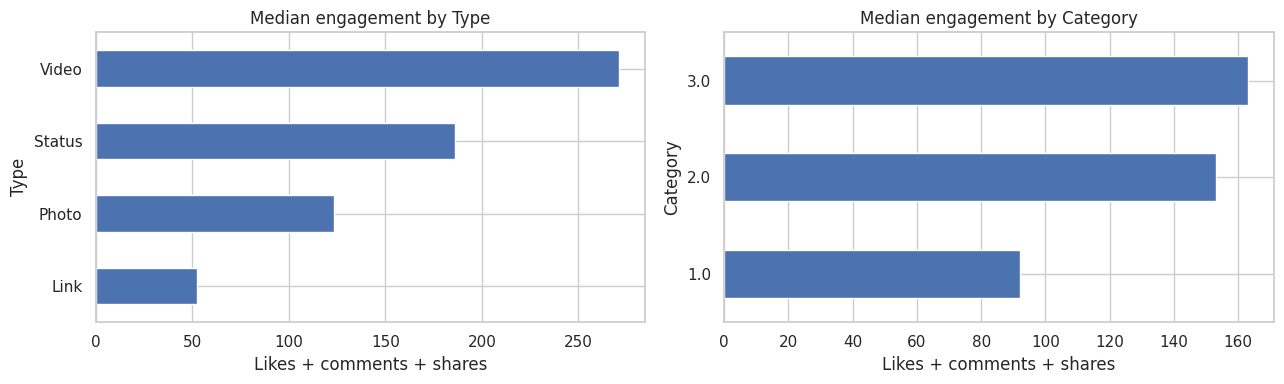

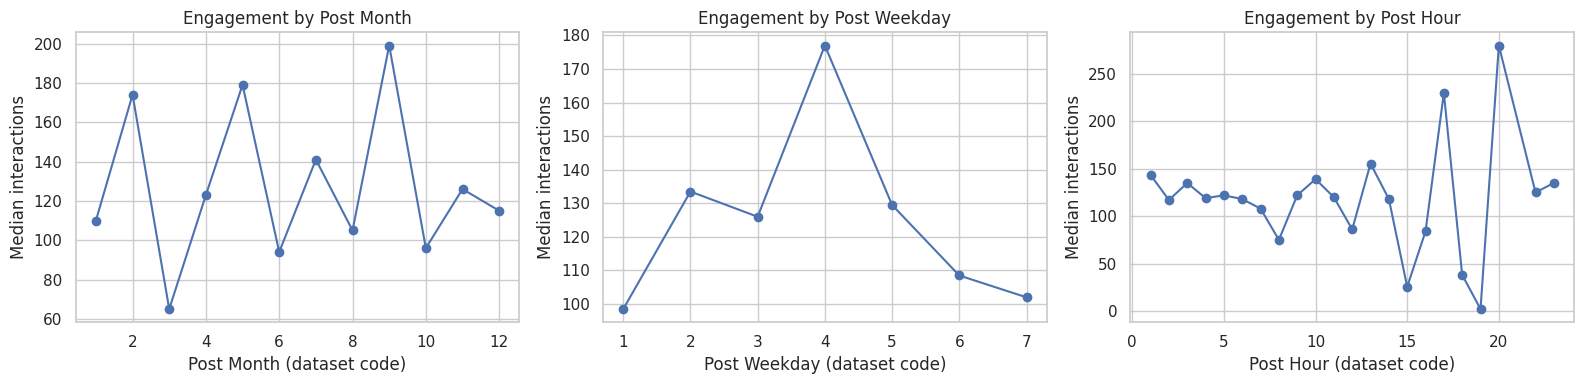

In [4]:
def summarize(key):
    return df.groupby(key,dropna=False,observed=True).agg(
        posts=('engagement','size'), observed=('engagement','count'),
        mean_engagement=('engagement','mean'),median_engagement=('engagement','median'),
        total_engagement=('engagement',lambda x:x.sum(min_count=1)),
        median_per_100_reached=('engagement_per_100_reached','median'))
tables = {k:summarize(k) for k in ['Type','Category','Post Month','Post Weekday','Post Hour']}
if 'Paid' in df: tables['Paid']=summarize('Paid')
for k,t in tables.items():
    print(k); display(t.sort_values('median_engagement',ascending=False))
    t.to_csv(OUT/f'facebook_{k.replace(" ","_")}.csv')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,key in zip(axes,['Type','Category']):
    tables[key]['median_engagement'].sort_values().plot.barh(ax=ax)
    ax.set(title=f'Median engagement by {key}',xlabel='Likes + comments + shares')
savefig('facebook_groups.png')
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,key in zip(axes,['Post Month','Post Weekday','Post Hour']):
    tables[key]['median_engagement'].plot(marker='o',ax=ax)
    ax.set(title=f'Engagement by {key}',ylabel='Median interactions',xlabel=key+' (dataset code)')
savefig('facebook_timing.png')

## 4. Relationships and distributions
Spearman correlation measures monotonic association and is less sensitive to extreme values than Pearson correlation. Reach and impressions may reflect paid distribution and content selection. Correlation cannot establish that one metric causes another.

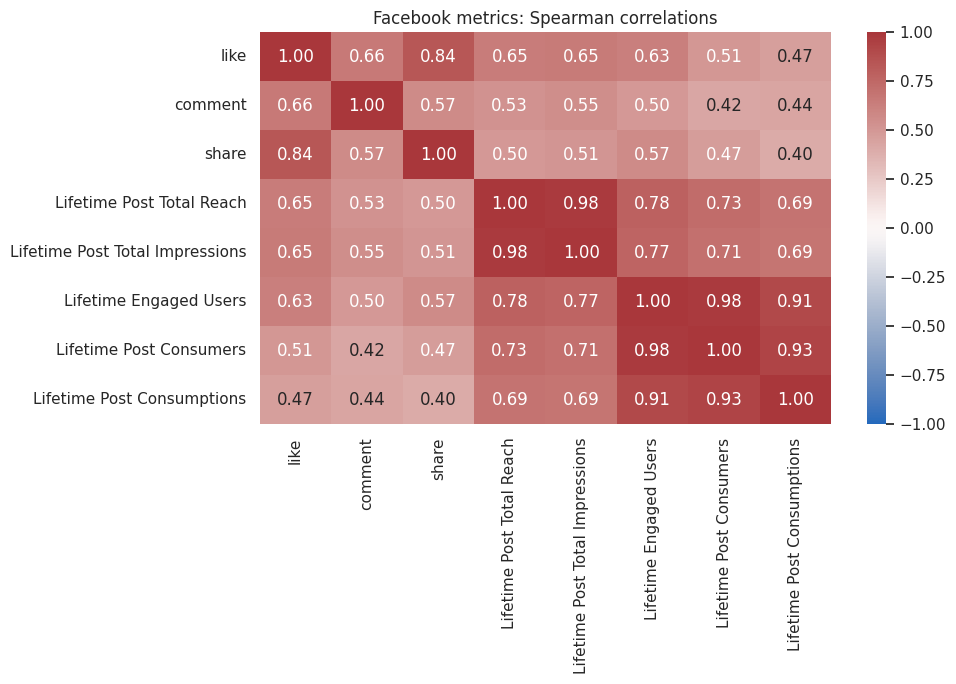

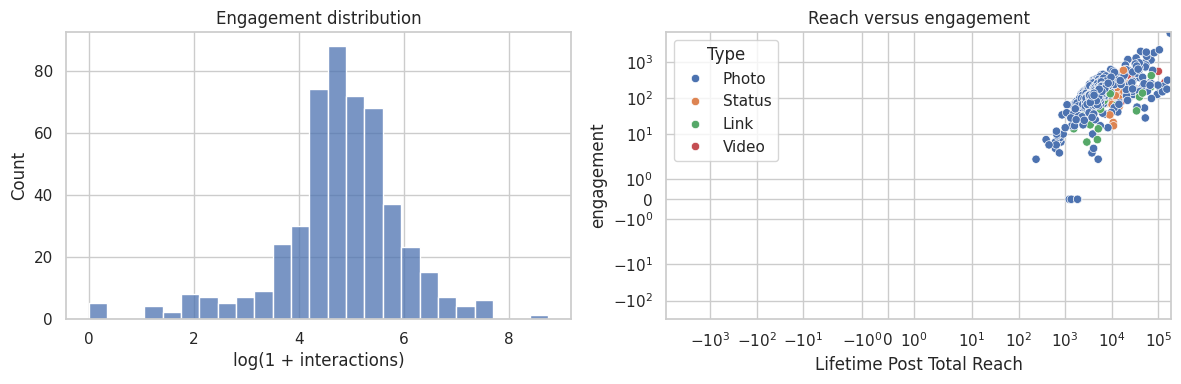

In [5]:
cols=['like','comment','share','Lifetime Post Total Reach','Lifetime Post Total Impressions']
extra=[c for c in ['Lifetime Engaged Users','Lifetime Post Consumers','Lifetime Post Consumptions'] if c in df]
corr=df[cols+extra].corr(method='spearman')
plt.figure(figsize=(10,7)); sns.heatmap(corr,annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='vlag')
plt.title('Facebook metrics: Spearman correlations'); savefig('facebook_correlations.png')
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.histplot(np.log1p(df.engagement.dropna()),bins=25,ax=axes[0]); axes[0].set(xlabel='log(1 + interactions)',title='Engagement distribution')
sns.scatterplot(data=df,x='Lifetime Post Total Reach',y='engagement',hue='Type',ax=axes[1])
axes[1].set(xscale='symlog',yscale='symlog',title='Reach versus engagement')
savefig('facebook_distribution_reach.png')

## 5. Evidence-based short report
The report is generated from this run, not prewritten numerical claims. Recommendations are hypotheses to test with controlled content experiments.

In [6]:
def leader(key):
    t=tables[key].dropna(subset=['median_engagement'])
    t=t[t.observed>=5].sort_values('median_engagement',ascending=False)
    if t.empty: return 'Insufficient observations (minimum five per group).'
    row=t.iloc[0]
    return f'{t.index[0]}: median {row.median_engagement:.2f} interactions, {int(row.observed)} observed posts.'
text=f"""# Facebook Metrics — findings
- Source file: {files[0].name}
- Raw rows: {len(raw)}; cleaned rows: {len(df)}.
- Complete engagement outcomes: {df.engagement.notna().sum()}.
- Median engagement: {df.engagement.median():.2f}; mean: {df.engagement.mean():.2f}.
- Leading post type by median engagement: {leader('Type')}
- Leading category: {leader('Category')}
- Leading posting-hour code: {leader('Post Hour')}

## Recommended actions
Trial the leading content types and categories while comparing reach-normalized engagement and group sizes. Test posting hours across repeated weeks rather than treating a historical peak as a universal best time. Evaluate paid and organic distribution separately where available.

## Limitations
Observational data; category and weekday meanings must be checked against the source documentation. Missing interactions are not zero. Timing, reach, paid distribution and content type may be confounded. These results describe this dataset, not current Facebook performance.

## Visual evidence
See ../figures/facebook_groups.png, facebook_timing.png, facebook_correlations.png and facebook_distribution_reach.png. Detailed group statistics and cleaning audit are in this directory.
"""
report('facebook_report.md',text)

# Facebook Metrics — findings
- Source file: dataset_Facebook.csv
- Raw rows: 500; cleaned rows: 500.
- Complete engagement outcomes: 496.
- Median engagement: 125.00; mean: 213.78.
- Leading post type by median engagement: Video: median 271.00 interactions, 7 observed posts.
- Leading category: 3.0: median 163.00 interactions, 155 observed posts.
- Leading posting-hour code: 13.0: median 155.50 interactions, 52 observed posts.

## Recommended actions
Trial the leading content types and categories while comparing reach-normalized engagement and group sizes. Test posting hours across repeated weeks rather than treating a historical peak as a universal best time. Evaluate paid and organic distribution separately where available.

## Limitations
Observational data; category and weekday meanings must be checked against the source documentation. Missing interactions are not zero. Timing, reach, paid distribution and content type may be confounded. These results describe this dataset, not cu